<a href="https://colab.research.google.com/github/Aishaa2030/ML-Game-Recommendation-System/blob/main/Game_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Game Recommendation System**..

# **DATA Initialization**


## **Data Inspection 🔍**

In [ ]:
# --- 1. Library Imports and Data Loading ---
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


In [ ]:
# Load the dataset
df = pd.read_csv("/content/steamgames_100k_rows.csv")

#نكتفي بـ 20% من البيانات أي 20 الف صف علشان التعليق
df = df.sample(frac=0.2, random_state=42)
print("✅ Data loaded successfully.")
df.head(20)


✅ Data loaded successfully.


,UserID,GameName,Hours,Behavior,Categories,Genres,is_recommended
75721,9181665.0,FOR HONOR™,1.0,purchase,Multi-player,['Action'],True
80184,11531502.0,Grand Theft Auto V,1.0,purchase,"Single-player, Multi-player","['Action', 'Adventure']",True
19864,1299092.0,No Man's Sky,249.0,play,"Single-player, Multi-player","['Adventure', 'Simulation']",True
76699,13862042.0,Grand Theft Auto V,3.4,play,Not Classified,['Strategy'],False
92991,6282199.0,Grand Theft Auto V,1.0,purchase,Not Classified,"['Action', 'Adventure']",False
76434,5425327.0,DayZ,1.0,purchase,"Single-player, Multi-player",['Horror'],True
84004,3102091.0,Grand Theft Auto V,1.0,purchase,Not Classified,"['Action', 'Adventure']",True
80917,14244902.0,The Witcher® 3: Wild Hunt,1.0,purchase,Single-player,['MOBA'],True
60767,11444706.0,Grand Theft Auto V,1.0,purchase,Not Classified,"['Action', 'Adventure']",True
50074,13277050.0,Path of Exile,1.0,purchase,"Single-player, Multi-player","['Action', 'RPG']",True


In [ ]:
print(df.columns)

Index(['UserID', 'GameName', 'Hours', 'Behavior', 'Categories', 'Genres',
       'is_recommended'],
      dtype='object')


In [ ]:
print('🧾INFO:')
df.info()

print('\n📐SHAPE:',df.shape)

print('\n🚫NULLS:')
print(df.isna().sum())

print('\n❗❗DUPLICATES:',df.duplicated().sum())

🧾INFO:
<class 'pandas.core.frame.DataFrame'>
Index: 20000 entries, 75721 to 42410
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          20000 non-null  float64
 1   GameName        20000 non-null  object 
 2   Hours           19998 non-null  float64
 3   Behavior        19998 non-null  object 
 4   Categories      20000 non-null  object 
 5   Genres          20000 non-null  object 
 6   is_recommended  20000 non-null  bool   
dtypes: bool(1), float64(2), object(4)
memory usage: 1.1+ MB

📐SHAPE: (20000, 7)

🚫NULLS:
UserID            0
GameName          0
Hours             2
Behavior          2
Categories        0
Genres            0
is_recommended    0
dtype: int64

❗❗DUPLICATES: 54


## **Data Cleaning 🧹**

In [ ]:
df.drop_duplicates(inplace=True)
df.drop(columns=['is_recommended'], inplace=True, errors='ignore')

print(df.shape)

(19946, 6)


In [ ]:
# --- 2. Data Inspection and Missing Value Handling ---
print("✅ Handling missing values...")

# Fill missing 'Hours' with the mean to maintain data distribution
df['Hours'] = df['Hours'].fillna(df['Hours'].mean())

# Fill missing 'Behavior' with the mode (most frequent value)
df['Behavior'] = df['Behavior'].fillna(df['Behavior'].mode()[0])

print(df.isnull().sum())
print("✅ Missing values have been handled.")

✅ Handling missing values...
UserID        0
GameName      0
Hours         0
Behavior      0
Categories    0
Genres        0
dtype: int64
✅ Missing values have been handled.


In [ ]:
print('🧾INFO:')
df.info()
print('\n🔍HEAD:')
df.head()

🧾INFO:
<class 'pandas.core.frame.DataFrame'>
Index: 19946 entries, 75721 to 42410
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   UserID      19946 non-null  float64
 1   GameName    19946 non-null  object 
 2   Hours       19946 non-null  float64
 3   Behavior    19946 non-null  object 
 4   Categories  19946 non-null  object 
 5   Genres      19946 non-null  object 
dtypes: float64(2), object(4)
memory usage: 1.1+ MB

🔍HEAD:


,UserID,GameName,Hours,Behavior,Categories,Genres
75721,9181665.0,FOR HONOR™,1.0,purchase,Multi-player,['Action']
80184,11531502.0,Grand Theft Auto V,1.0,purchase,"Single-player, Multi-player","['Action', 'Adventure']"
19864,1299092.0,No Man's Sky,249.0,play,"Single-player, Multi-player","['Adventure', 'Simulation']"
76699,13862042.0,Grand Theft Auto V,3.4,play,Not Classified,['Strategy']
92991,6282199.0,Grand Theft Auto V,1.0,purchase,Not Classified,"['Action', 'Adventure']"


In [ ]:
# --- 3. Data Cleaning and Type Conversion ---
print("✅ Cleaning and converting data types...")

# Drop unwanted behaviors and create a copy to avoid warnings
df = df[df["Behavior"].isin(["play", "purchase"])].copy()

# Convert data types efficiently
df = df.astype({
    "GameName": "string",
    "Behavior": "string",
    "UserID": "Int64"
})

print('🧾New INFO:')
df.info()
print("✅ Data types converted successfully.")

✅ Cleaning and converting data types...
🧾New INFO:
<class 'pandas.core.frame.DataFrame'>
Index: 19946 entries, 75721 to 42410
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   UserID      19946 non-null  Int64  
 1   GameName    19946 non-null  string 
 2   Hours       19946 non-null  float64
 3   Behavior    19946 non-null  string 
 4   Categories  19946 non-null  object 
 5   Genres      19946 non-null  object 
dtypes: Int64(1), float64(1), object(2), string(2)
memory usage: 1.1+ MB
✅ Data types converted successfully.


✅ Starting Outliers Detection in 'Hours' column...
🚨 Outliers detected: 1002 values
Lower Bound=-25.40, Upper Bound=45.00
Sample of detected outliers:
19864    249.0
30959     51.0
64290     67.0
82585     75.0
31183    100.0
Name: Hours, dtype: float64


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


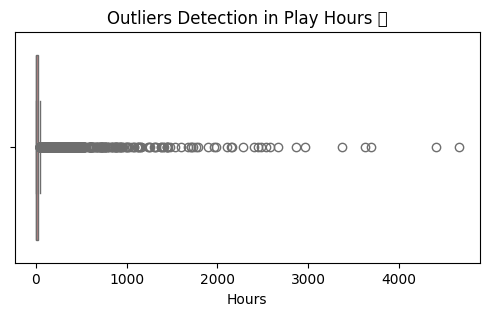

In [ ]:
# --- 4  Outliers Detection and Visualization  ---
print("✅ Starting Outliers Detection in 'Hours' column...")

hours_play = df[df["Behavior"]=="play"]["Hours"]

# Calculate IQR to define outliers
Q1, Q3 = np.percentile(hours_play, [25, 75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR

# Identify outliers
outliers = hours_play[(hours_play < lower) | (hours_play > upper)]

print(f"🚨 Outliers detected: {len(outliers)} values")
print(f"Lower Bound={lower:.2f}, Upper Bound={upper:.2f}")

# Check if any outliers were found before printing
if not outliers.empty:
    print("Sample of detected outliers:")
    print(outliers.head())
else:
    print("No outliers were detected.")

# Visualize the outliers using a box plot
plt.figure(figsize=(6,3))
sns.boxplot(x=hours_play, color="lightcoral")
plt.title("Outliers Detection in Play Hours 🚨")
plt.show()

✅ Capping outliers to clean the 'Hours' column...


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129506 (\N{BILLED CAP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


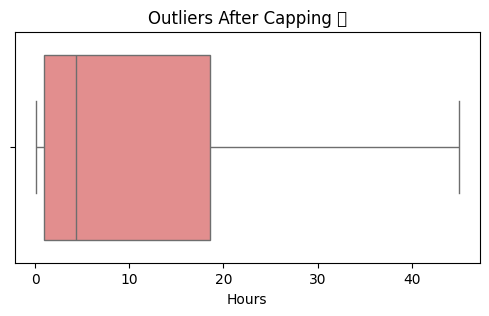

✅ Outliers have been capped successfully. The data is now ready for aggregation.


In [ ]:
# --- 5. Handling Outliers by Capping ---
# Capping replaces outliers with the upper/lower bound to reduce their effect.
print("✅ Capping outliers to clean the 'Hours' column...")

# Calculate the upper bound again, based on the `Hours` for 'play' behavior
hours_play = df[df["Behavior"]=="play"]["Hours"]
Q1, Q3 = np.percentile(hours_play, [25, 75])
IQR = Q3 - Q1
upper_bound = Q3 + 1.5*IQR

# Apply capping to the original 'Hours' column in the main DataFrame
df['Hours'] = np.where(df['Hours'] > upper_bound, upper_bound, df['Hours'])

# Re-visualize the data to confirm capping
plt.figure(figsize=(6,3))
sns.boxplot(x=df[df["Behavior"]=="play"]["Hours"], color="lightcoral")
plt.title("Outliers After Capping 🧢")
plt.show()

print("✅ Outliers have been capped successfully. The data is now ready for aggregation.")

## **Encoding 🔢**

In [ ]:
# --- 6. Process Categorical Columns with One-Hot Encoding ---
# This is a crucial step to prepare genres and categories for the model.
print("✅ Processing categorical columns (Genres, Categories)...")

# Create dummy variables for each genre and category
genres_encoded = df['Genres'].str.get_dummies(sep=';')
categories_encoded = df['Categories'].str.get_dummies(sep=';')

print("✅ Categorical columns successfully processed.")

✅ Processing categorical columns (Genres, Categories)...
✅ Categorical columns successfully processed.


## **Feature Engineering 🛠️**

In [ ]:
# --- 7. Aggregating all features for the clustering model ---
# This step combines user behavior stats with genre/category preferences.
print("✅ Merging all features for the model...")

# A. Aggregate user behavior stats
user_stats = df.groupby('UserID').agg(
    total_play_hours=('Hours', 'sum'),
    purchase_count=('Behavior', lambda x: (x == 'purchase').sum()),
    total_interactions=('Behavior', 'count')
).reset_index()
user_stats['avg_playtime'] = user_stats['total_play_hours'] / user_stats['total_interactions']
# B. Aggregate the encoded genre and category features by user
# We'll concatenate the original 'UserID' column with the encoded features
# and then group by the UserID to sum the genre/category counts.
df_with_encoded_features = pd.concat([df['UserID'], genres_encoded, categories_encoded], axis=1)
user_features_encoded = df_with_encoded_features.groupby('UserID').sum().reset_index()

# C. Merge the behavior stats with the genre/category features
final_features = pd.merge(user_stats, user_features_encoded, on='UserID', how='outer').fillna(0)

# D. Calculate purchase ratio
final_features["purchase_ratio"] = (final_features["purchase_count"] / final_features["total_interactions"].replace(0, np.nan)).fillna(0)

print('🛠️ Final Feature Set (Content-Based):\n')
print(final_features.head())

✅ Merging all features for the model...
🛠️ Final Feature Set (Content-Based):

   UserID  total_play_hours  purchase_count  total_interactions  avg_playtime  \
0     369               3.3               0                   1           3.3   
1     790               1.0               1                   1           1.0   
2    2042               1.0               1                   1           1.0   
3    4514               3.2               0                   1           3.2   
4    4884               4.7               0                   1           4.7   

   ['Action', 'Adventure']  ['Action', 'Fighting']  ['Action', 'Horror']  \
0                        0                       0                     0   
1                        0                       0                     0   
2                        0                       0                     0   
3                        0                       0                     0   
4                        1                       0    

## **Visualization 📊**

✅ Visualizing top games and genres...


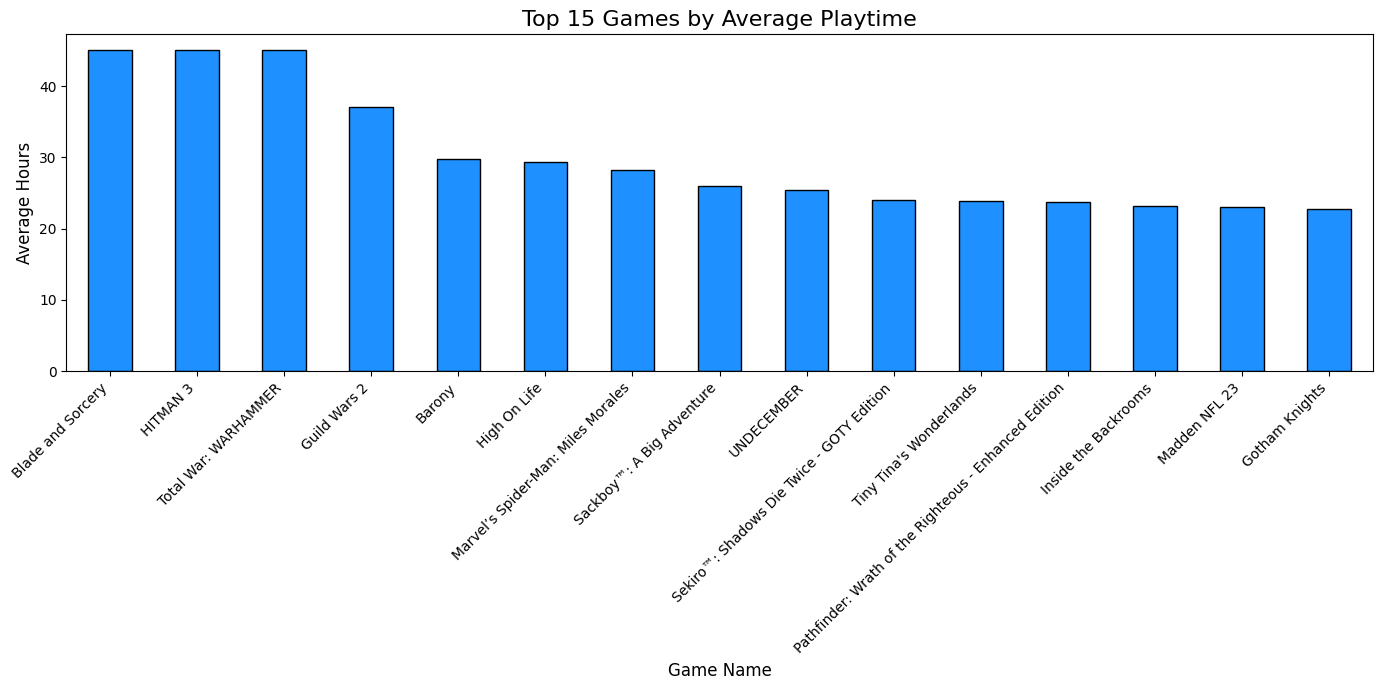

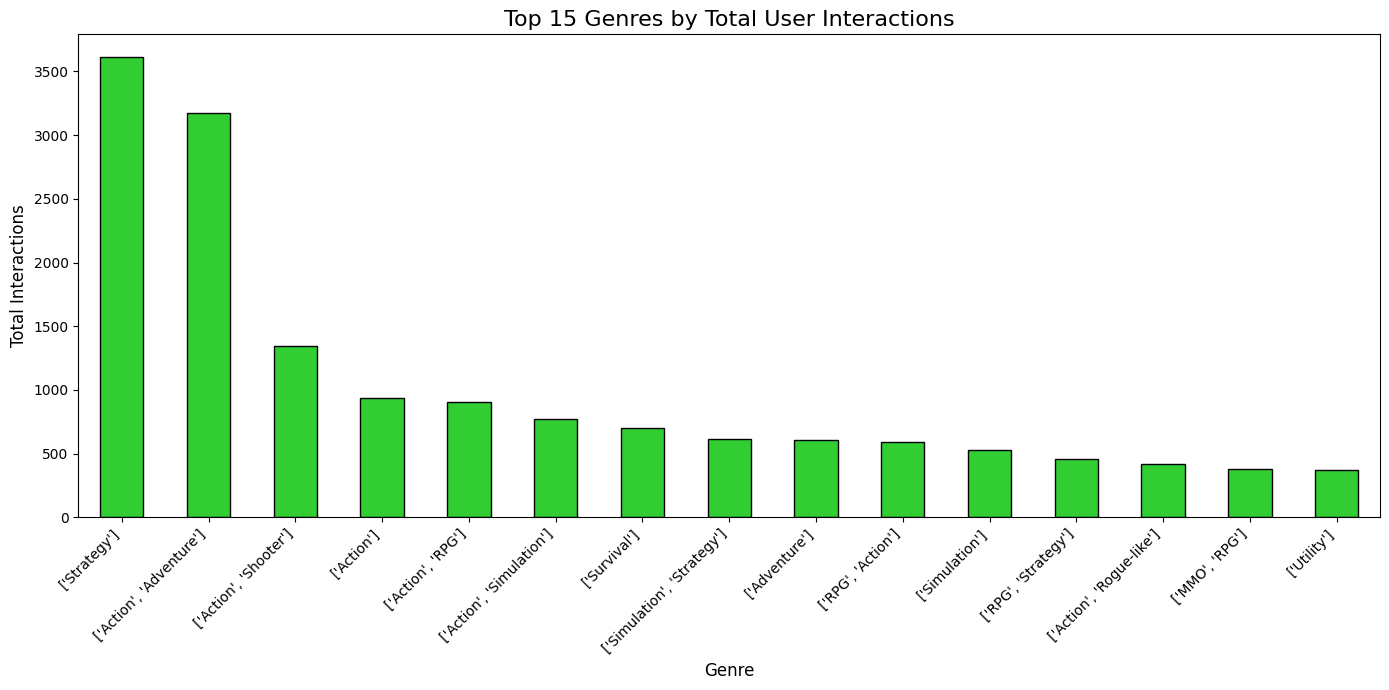

✅ Visualization complete.


In [ ]:
# --- 8. Visualization for Data Exploration 📊 ---
# The goal is to visually inspect the most popular games and genres.
print("✅ Visualizing top games and genres...")

# A. Plot Top 15 Games by Average Playtime
# We use the original dataframe to get the raw playtime data
avg_playtime_per_game = df[df["Behavior"] == "play"].groupby("GameName", observed=True)["Hours"].mean().nlargest(15)

plt.figure(figsize=(14, 7))
avg_playtime_per_game.plot(kind="bar", color="dodgerblue", edgecolor="black")
plt.title("Top 15 Games by Average Playtime", fontsize=16)
plt.ylabel("Average Hours", fontsize=12)
plt.xlabel("Game Name", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# B. Plot Top 15 Genres by Total User Interactions
# We use the encoded data to sum up all user interactions per genre
genre_interactions = genres_encoded.sum().nlargest(15)

plt.figure(figsize=(14, 7))
genre_interactions.plot(kind="bar", color="limegreen", edgecolor="black")
plt.title("Top 15 Genres by Total User Interactions", fontsize=16)
plt.ylabel("Total Interactions", fontsize=12)
plt.xlabel("Genre", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("✅ Visualization complete.")

## **Normalization 📏**

In [ ]:
# --- 9. Data Scaling (Normalization) ---
print("✅ Scaling numeric features...")

numeric_cols = final_features.select_dtypes(include=np.number).columns.tolist()
numeric_cols.remove('UserID')

scaler = StandardScaler()
final_features[numeric_cols] = scaler.fit_transform(final_features[numeric_cols])

print('✅ Numeric features normalized.')

✅ Scaling numeric features...
✅ Numeric features normalized.


# **Unsupervised Clustering ( K-Means )**

## **Finding Number of Clusters 🧩**

✅ Calculating inertia and silhouette scores...


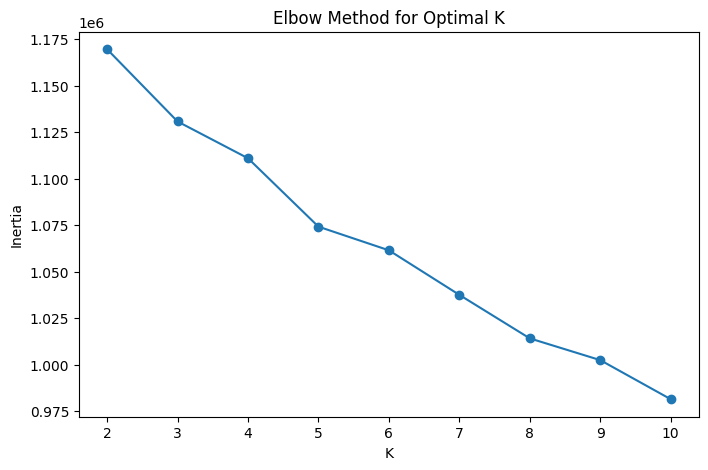

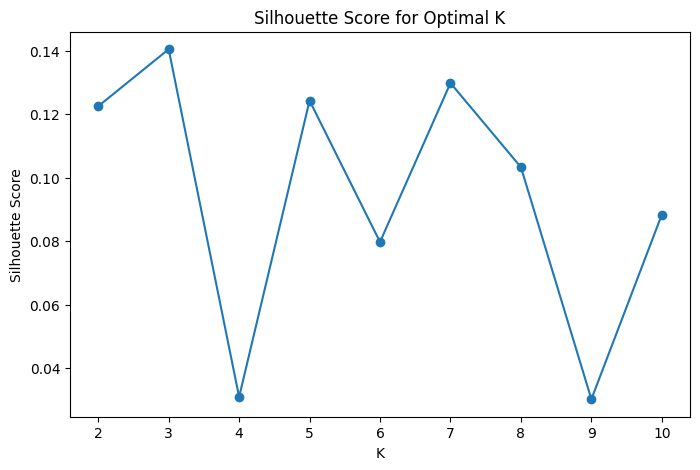

✅ Optimal k values calculated


In [ ]:
# --- 10. Determining the Optimal Number of Clusters (Elbow + Silhouette) ---
# The goal is to find the best value for k for the K-Means model.
print("✅ Calculating inertia and silhouette scores...")

inertias = []
sil_scores = []
clustering_data = final_features.drop(columns='UserID') # Exclude UserID from clustering

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(clustering_data)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(clustering_data, km.labels_))

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertias, marker="o")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.show()

# Plot the Silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), sil_scores, marker="o")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Optimal K")
plt.show()

print("✅ Optimal k values calculated")

In [ ]:
# --- 11. Apply K-Means Clustering with Optimal K ---
print("✅ Applying K-Means with the optimal number of clusters...")

optimal_k = 4

# Fit the model to the data
kmeans_model = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
final_features['Cluster'] = kmeans_model.fit_predict(final_features.drop(columns='UserID'))

print(f"✅ Users have been grouped into {optimal_k} clusters.")
print("\nSample of user clusters:")
print(final_features[['UserID', 'Cluster']].head())

✅ Applying K-Means with the optimal number of clusters...
✅ Users have been grouped into 4 clusters.

Sample of user clusters:
   UserID  Cluster
0     369        0
1     790        1
2    2042        1
3    4514        0
4    4884        0


## **KMeans Clustering ⚙️**

In [ ]:
# --- 12.  Scaling, PCA, and K-Means ---
from sklearn.metrics import davies_bouldin_score

# A. Select features for clustering
features_to_cluster = final_features.select_dtypes(include=np.number).columns.tolist()
features_to_cluster.remove('UserID')

# B. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(final_features[features_to_cluster])

# C. Apply Principal Component Analysis (PCA)
# We reduce the data to a smaller number of components (e.g., 5)
pca = PCA(n_components=5, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"✅ Data dimensionality reduced from {X_scaled.shape[1]} to {X_pca.shape[1]} features.")

# D. Apply K-Means to the PCA-transformed data
optimal_k = 4
kmeans_model = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
final_features['Cluster'] = kmeans_model.fit_predict(X_pca)

# E. Evaluate the model on the PCA-transformed data
sil_score = silhouette_score(X_pca, final_features['Cluster'])
db_index = davies_bouldin_score(X_pca, final_features['Cluster'])

print('✅ K-Means Clustering applied successfully.')
print("✨K-Means silhouette:", sil_score)
print("📐K-Means DB index:", db_index)

✅ Data dimensionality reduced from 64 to 5 features.
✅ K-Means Clustering applied successfully.
✨K-Means silhouette: 0.358348890508477
📐K-Means DB index: 0.9145167171398169


## **DBSCAN Clustering 🌌**

In [ ]:
# --- 13. Apply DBSCAN Clustering ---
from sklearn.cluster import DBSCAN, KMeans

print("✅ Applying DBSCAN to find density-based clusters...")

# The data used for clustering
clustering_data = final_features.drop(columns='UserID')

# Iterate through different epsilon values to find the best fit
for eps in [0.3, 0.5, 0.7, 1.0]:
    db = DBSCAN(eps=eps, min_samples=10)
    db_labels = db.fit_predict(clustering_data)
    n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
    n_noise = np.sum(db_labels == -1)

    if n_clusters > 1:
        # Calculate silhouette score for the non-noise points
        sil = silhouette_score(clustering_data[db_labels!=-1], db_labels[db_labels!=-1])
    else:
        sil = np.nan

    print(f"eps={eps}: clusters={n_clusters}, noise={n_noise}, silhouette={sil}")

✅ Applying DBSCAN to find density-based clusters...
eps=0.3: clusters=197, noise=1583, silhouette=0.9512555420606973
eps=0.5: clusters=202, noise=1234, silhouette=0.9447182607112072
eps=0.7: clusters=199, noise=982, silhouette=0.9298990856251319
eps=1.0: clusters=208, noise=769, silhouette=0.9191598592396825


In [ ]:
# --- 14. Compare K-Means and DBSCAN Results ---
# This cell compares the cluster sizes and assignments of the two models.
print("✅ Comparing cluster results...")

# A. Apply DBSCAN clustering with the chosen parameters
db = DBSCAN(eps=0.7, min_samples=10)
db_labels = db.fit_predict(final_features.drop(columns='UserID'))
final_features["DBSCAN_Cluster"] = db_labels

# B. Display the size of each cluster for both models
print('\n⚖️Comparing clusters of K-Means to DBSCAN:')
print('K-Means Cluster Sizes:')
print(final_features["Cluster"].value_counts())

print('\n')

print('DBSCAN Cluster Sizes:')
print(final_features["DBSCAN_Cluster"].value_counts())

# C. Show the cluster assignment for the first few rows
print('\n🧩Showing the cluster each row belongs to:')
print(final_features[['UserID', 'Cluster', 'DBSCAN_Cluster']].head())

✅ Comparing cluster results...

⚖️Comparing clusters of K-Means to DBSCAN:
K-Means Cluster Sizes:
Cluster
2    10400
1     5694
0     2733
3      372
Name: count, dtype: int64


DBSCAN Cluster Sizes:
DBSCAN_Cluster
 27     1054
-1       982
 4       692
 30      675
 14      639
        ... 
 163      11
 194      10
 191      10
 122      10
 132      10
Name: count, Length: 200, dtype: int64

🧩Showing the cluster each row belongs to:
   UserID  Cluster  DBSCAN_Cluster
0     369        2               0
1     790        2              -1
2    2042        2               1
3    4514        2               2
4    4884        1               3


## **Visualizing Clusters 🧮**

✅ Visualizing K-Means vs. DBSCAN clusters...


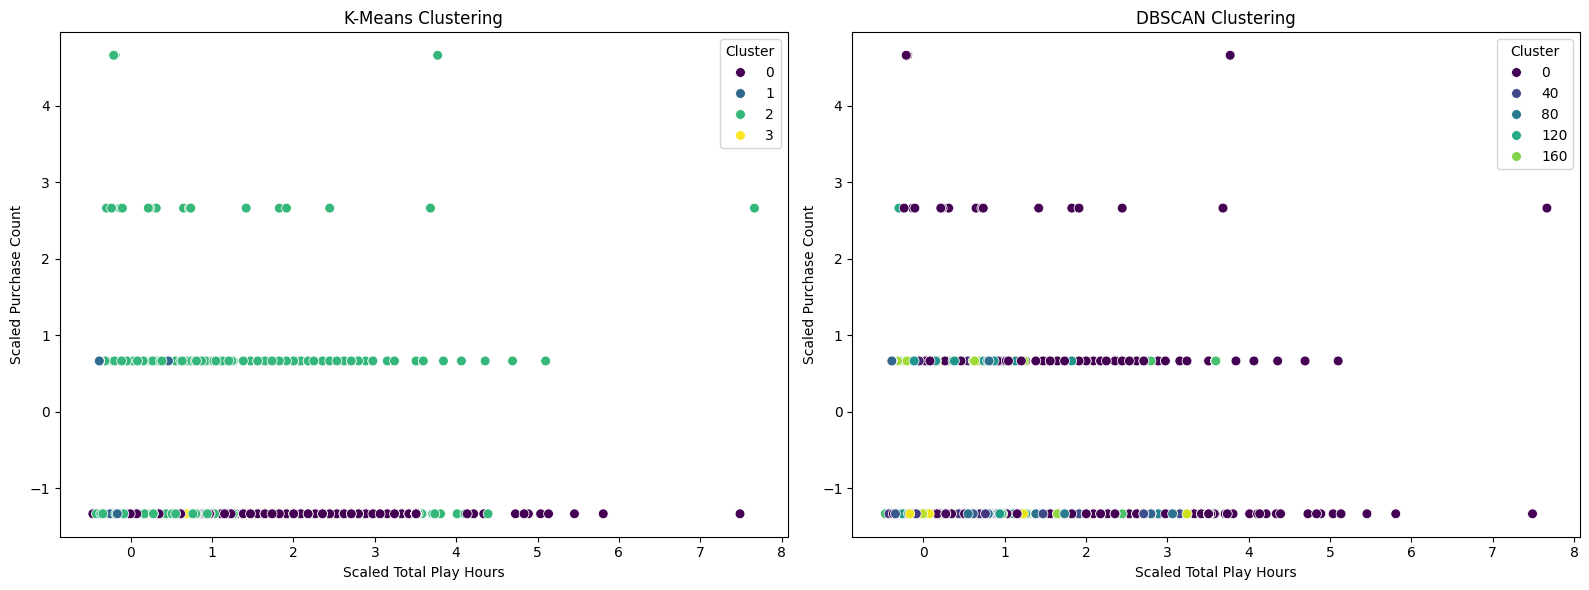

✅ Visualization complete. You can now clearly see the difference between the two models.


In [ ]:
# --- 15. Visualize K-Means and DBSCAN Clusters ---
# This visual comparison helps in understanding the results of both models.
print("✅ Visualizing K-Means vs. DBSCAN clusters...")

# Use the scaled features for plotting, but retrieve them from final_features
scaled_features_for_plot = final_features.drop(columns=['UserID', 'Cluster', 'DBSCAN_Cluster'])
scaled_features_for_plot.columns = [f'Scaled_{col}' for col in scaled_features_for_plot.columns]

# Create a figure with two subplots for comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visualize K-Means clusters
sns.scatterplot(x=scaled_features_for_plot['Scaled_total_play_hours'],
                y=scaled_features_for_plot['Scaled_purchase_count'],
                hue=final_features['Cluster'],
                palette='viridis',
                ax=axes[0],
                s=50)
axes[0].set_title('K-Means Clustering')
axes[0].set_xlabel('Scaled Total Play Hours')
axes[0].set_ylabel('Scaled Purchase Count')
axes[0].legend(title='Cluster')

# Visualize DBSCAN clusters
sns.scatterplot(x=scaled_features_for_plot['Scaled_total_play_hours'],
                y=scaled_features_for_plot['Scaled_purchase_count'],
                hue=final_features['DBSCAN_Cluster'],
                palette='viridis',
                ax=axes[1],
                s=50)
axes[1].set_title('DBSCAN Clustering')
axes[1].set_xlabel('Scaled Total Play Hours')
axes[1].set_ylabel('Scaled Purchase Count')
axes[1].legend(title='Cluster')

plt.tight_layout()
plt.show()

print("✅ Visualization complete. You can now clearly see the difference between the two models.")

## **Cluster Profiling 🎯**

In [ ]:
# --- 16. Analyzing Cluster Characteristics ---
# The goal is to understand the profile of each cluster by calculating
# the average of all features within each group.
print("✅ Analyzing the characteristics of each cluster...")

# A. Group the data by cluster and calculate the mean for all features
# We'll drop the UserID and DBSCAN_Cluster columns as they are not needed for profiling
cluster_analysis_data = final_features.drop(columns=['UserID', 'DBSCAN_Cluster'])
cluster_profiles = cluster_analysis_data.groupby('Cluster').mean()

# B. Display the final cluster profiles
print('🛠️ Average Features for Each Cluster:')
print(cluster_profiles.to_string()) # Use to_string() for better display

print("\n✅ Cluster analysis complete. The table above provides the profile for each user segment.")

✅ Analyzing the characteristics of each cluster...
🛠️ Average Features for Each Cluster:
         total_play_hours  purchase_count  total_interactions  avg_playtime  ['Action', 'Adventure']  ['Action', 'Fighting']  ['Action', 'Horror']  ['Action', 'RPG']  ['Action', 'Rogue-like']  ['Action', 'Shooter']  ['Action', 'Simulation']  ['Action', 'Strategy']  ['Action', 'Survival']  ['Action', 'VR']  ['Action']  ['Adventu']  ['Adventure', 'Action']  ['Adventure', 'Co-op']  ['Adventure', 'RPG']  ['Adventure', 'Sandbox']  ['Adventure', 'Simulation']  ['Adventure', 'Western']  ['Adventure']  ['Battle Royale', 'Shooter']  ['Card Game']  ['Casual']  ['Fighting']  ['Horror', 'Survival']  ['Horror']  ['MMO', 'RPG']  ['MOBA', 'Strategy']  ['MOBA']  ['Music']  ['Not Classified']  ['Puzzle']  ['RPG', 'Action']  ['RPG', 'Adventure']  ['RPG', 'MMO']  ['RPG', 'Strategy']   ['RPG']  ['Racing', 'Simulation']  ['Racing']  ['Rhythm']  ['Shooter']  ['Simulation', 'Social']  ['Simulation', 'Strategy', 'RPG']  [

| المجموعة | الاسم المقترح | السلوك المميز |
| :--- | :--- | :--- |
| **0** | **المستخدمون التقنيون** | يفضلون أدوات المنصة، ونادرًا ما يلعبون. |
| **1** | **لاعبو الأكشن الجماعي** | نشطون، يفضلون الألعاب الجماعية وألعاب الشوتر. |
| **2** | **اللاعبون المحترفون** | الأكثر إنفاقًا وتفاعلًا، يفضلون ألعاب المغامرات. |
| **3** | **عشاق الألعاب الفردية** | يفضلون الألعاب الفردية من نوع 'Rogue-like'. |

# **Supervised Prediction**


## **Data Splitting for Supervised Learning**

In [ ]:
### Data Splitting for Supervised Learning ###
# --- 17. Define inputs (X) and outputs (y) ---
from sklearn.model_selection import train_test_split
genres_columns = [col for col in final_features.columns if col.startswith('user_genres_str_')]
categories_columns = [col for col in final_features.columns if col.startswith('user_categories_str_')]

# The list of all feature columns (X)
X_columns = ['total_play_hours', 'avg_playtime'] + genres_columns + categories_columns
X = final_features[X_columns].copy()

# The target variable (y)
y = (final_features['purchase_ratio'] > 0).astype(int)

# --- Drop any rows with missing values to avoid errors during training ---
X = X.dropna()
y = y.loc[X.index]

# --- 3. Split the data ---
X_train, X_test, y_train_binary, y_test_binary = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"✅ Data split complete.")
print(f"Number of training rows: {X_train.shape[0]}")
print(f"Number of testing rows: {X_test.shape[0]}")

✅ Data split complete.
Number of training rows: 15359
Number of testing rows: 3840


## **Model training and comparison**

In [ ]:
# --- 18. Train the models ---
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

print("✅ Starting training for both models...")
log_reg = LogisticRegression(random_state=42, solver='liblinear')
log_reg.fit(X_train, y_train_binary)
print("✅ Logistic Regression model trained successfully.")

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train_binary)
print("✅ Random Forest model trained successfully.")

✅ Starting training for both models...
✅ Logistic Regression model trained successfully.
✅ Random Forest model trained successfully.


## **Model Evaluation and Comparison**

In [ ]:
# --- 19 ---
# --- 1. Evaluate the Logistic Regression model ---
print("\n✅ Evaluating the Logistic Regression model:")
y_pred_log_reg = log_reg.predict(X_test)
print(classification_report(y_test_binary, y_pred_log_reg))
print("- Confusion Matrix:")
print(confusion_matrix(y_test_binary, y_pred_log_reg))

# --- 2. Evaluate the Random Forest model ---
print("\n✅ Evaluating the Random Forest model:")
y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test_binary, y_pred_rf))
print("- Confusion Matrix:")
print(confusion_matrix(y_test_binary, y_pred_rf))


✅ Evaluating the Logistic Regression model:
              precision    recall  f1-score   support

           0       1.00      0.63      0.77      1367
           1       0.83      1.00      0.91      2473

    accuracy                           0.87      3840
   macro avg       0.91      0.81      0.84      3840
weighted avg       0.89      0.87      0.86      3840

- Confusion Matrix:
[[ 858  509]
 [   2 2471]]

✅ Evaluating the Random Forest model:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      1367
           1       0.99      1.00      0.99      2473

    accuracy                           0.99      3840
   macro avg       0.99      0.99      0.99      3840
weighted avg       0.99      0.99      0.99      3840

- Confusion Matrix:
[[1341   26]
 [   2 2471]]


#  **Final User Interface (Gradio)**



In [ ]:
import gradio as gr
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# --- 1. إعداد البيانات وتدريب النماذج (كامل ومصحح) ---
print("✅ جارٍ إعداد البيانات وتدريب النماذج...")

# أ. تحميل البيانات
file_path = 'steamgames_100k_rows.csv'
try:
    df = pd.read_csv(file_path)
    # أخذ عينة من البيانات لسرعة المعالجة
    df = df.sample(frac=0.2, random_state=42).copy()
except FileNotFoundError:
    print("❌ خطأ: لم يتم العثور على الملف. تأكد من أن الملف تم تحميله مباشرة إلى Colab.")
    exit()

# ب. تنظيف البيانات وملء القيم المفقودة
df['Hours'] = df['Hours'].fillna(0)
df['Genres'] = df['Genres'].fillna('Not Available')
df['Categories'] = df['Categories'].fillna('Not Available')

# ج. بناء الخصائص السلوكية للمستخدمين
try:
    playtime = df[df["Behavior"] == "play"].groupby("UserID", observed=True)["Hours"].sum().rename("total_play_hours")
    purchases = df[df["Behavior"] == "purchase"].groupby("UserID", observed=True).size().rename("purchase_count")
    interactions = df.groupby("UserID", observed=True).size().rename("total_interactions")
    avg_play = df[df["Behavior"] == "play"].groupby("UserID", observed=True)["Hours"].mean().rename("avg_playtime")

    # دمج البيانات السلوكية مع بيانات الأنواع والفئات
    user_genres = df.groupby("UserID", observed=True)["Genres"].agg(lambda x: ','.join(x)).rename("user_genres_str")
    user_categories = df.groupby("UserID", observed=True)["Categories"].agg(lambda x: ','.join(x)).rename("user_categories_str")

    stats = pd.concat([playtime, purchases, interactions, avg_play, user_genres, user_categories], axis=1).fillna(0).reset_index()
    stats["purchase_ratio"] = (stats["purchase_count"] / stats["total_interactions"].replace(0, np.nan)).fillna(0)
except Exception as e:
    print(f"❌ خطأ: فشل في بناء الخصائص السلوكية. الخطأ: {e}")
    exit()

if stats.empty:
    print("❌ خطأ: لا يوجد أي مستخدمين صالحين في العينة التي تم تحليلها.")
    exit()

# د. معالجة الأعمدة الفئوية باستخدام One-Hot Encoding
genres_dummies = stats['user_genres_str'].str.get_dummies(sep=',')
categories_dummies = stats['user_categories_str'].str.get_dummies(sep=',')
stats_final = pd.concat([stats, genres_dummies, categories_dummies], axis=1)

# هـ. التجميع (Clustering)
try:
    best_k = 4
    # الآن نستخدم جميع الميزات (السلوكية والفئوية) للتجميع
    feature_cols = [col for col in stats_final.columns if col not in ['UserID', 'total_interactions', 'user_genres_str', 'user_categories_str']]

    X_features = stats_final[feature_cols].copy()
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_features)

    kmeans = KMeans(n_clusters=best_k, n_init="auto", random_state=42)
    stats['Cluster'] = kmeans.fit_predict(X_scaled)
except Exception as e:
    print(f"❌ خطأ: فشل في عملية التجميع. الخطأ: {e}")
    exit()

# و. التنبؤ (Prediction)
try:
    # --- التعديل هنا: استخدام stats_final لتدريب النموذج ---
    X_log = stats_final.drop(columns=['UserID', 'user_genres_str', 'user_categories_str'])
    y_log = stats_final['purchase_ratio'].apply(lambda x: 1 if x > 0 else 0)

    log_reg = LogisticRegression(random_state=42, solver='liblinear')
    log_reg.fit(X_log, y_log)
except Exception as e:
    print(f"❌ خطأ: فشل في تدريب نموذج التنبؤ. الخطاء: {e}")
    exit()

print("✅ تم الإعداد بنجاح. الواجهة جاهزة للتشغيل.")

# --- 2. تعريف الدوال للواجهة التفاعلية (محدث) ---

def user_profile(uid):
    user_data = stats.loc[stats['UserID'] == uid]
    if user_data.empty:
        return f"**Error:** User {uid} not found."

    cluster_name_map = {
        0: "المستخدمون الفنيون (Technical Users)",
        1: "لاعبو الأكشن الجماعي (Multiplayer Action Gamers)",
        2: "اللاعبون المحترفون (Pro Gamers)",
        3: "عشاق الألعاب الفردية (Single-player Lovers)"
    }
    cluster_name = cluster_name_map.get(user_data['Cluster'].iloc[0], "غير معروفة (Unknown)")

    return f"""
<div style='color: #4CAF50; font-size: 1.2em; font-weight: bold;'>👤 User Profile</div>

- **User ID**: {int(uid)}
- **Total Play Hours**: {int(user_data['total_play_hours'].iloc[0])} hours
- **Purchases**: {int(user_data['purchase_count'].iloc[0])}
- **User Type**: {cluster_name}
    """

def purchase_prediction(uid):
    # الحصول على البيانات من stats_final التي تحتوي على كل الميزات
    user_data = stats_final.loc[stats_final['UserID'] == uid].copy()
    if user_data.empty:
        return f"**Error:** User {uid} not found."

    # استخدام نفس الميزات التي تم تدريب النموذج عليها
    user_features = user_data.drop(columns=['UserID', 'user_genres_str', 'user_categories_str'])
    purchase_prob = log_reg.predict_proba(user_features)[0][1]

    prediction_text = "Highly Likely to Buy" if purchase_prob > 0.5 else "Unlikely to Buy"
    purchase_prob_percent = round(purchase_prob * 100, 2)

    return f"""
<div style='color: #4CAF50; font-size: 1.2em; font-weight: bold;'>🔮 Purchase Prediction</div>

- **Prediction**: {prediction_text}
- **Probability**: {purchase_prob_percent}%
    """

def get_recommendations(uid):
    user_data = stats.loc[stats['UserID'] == uid].copy()
    if user_data.empty:
        return "No data found for this user."

    user_cluster = user_data['Cluster'].iloc[0]

    interacted_games = df[df['UserID'] == uid]['GameName'].unique()
    cluster_users_df = df[df['UserID'].isin(stats[stats['Cluster'] == user_cluster]['UserID'])]

    popular_in_cluster = cluster_users_df[~cluster_users_df['GameName'].isin(interacted_games)]

    top_recommendations = popular_in_cluster['GameName'].value_counts().head(5).index.tolist()

    if not top_recommendations:
        return "No new recommendations for this user based on their cluster."

    output_html = ""
    has_genres = 'Genres' in df.columns
    has_categories = 'Categories' in df.columns

    for game_name in top_recommendations:
        game_info = df[df['GameName'] == game_name].iloc[0]
        game_genres = game_info['Genres'] if has_genres else "Not Available"
        game_categories = game_info['Categories'] if has_categories else "Not Available"

        output_html += f"""
        <div class="rec-card" style="
            display: flex;
            align-items: center;
            background-color: #ffffff;
            border: 1px solid #e0e0e0;
            border-radius: 8px;
            box-shadow: 2px 2px 0px #d0d0d0;
            padding: 15px;
            margin-bottom: 15px;
            transition: transform 0.2s;
        ">
            <div class="game-cover" style="
                width: 80px;
                height: 80px;
                background-color: #ddd;
                border: 2px solid #333;
                box-shadow: 3px 3px 0px #999;
                border-radius: 8px;
                margin-right: 15px;
                display: flex;
                align-items: center;
                justify-content: center;
                font-size: 40px;
                color: #aaa;
            ">🎮</div>
            <div style="flex-grow: 1;">
                <h3 style="color: #4CAF50; margin: 0 0 5px 0; font-size: 1.1em; font-weight: 600;">{game_name}</h3>
                <p style="color: #666; font-size: 0.9em; margin: 0 0 8px 0;">
                    <span style="color: #999;">🕹️ Genre:</span> {game_genres}
                    <br>
                    <span style="color: #999;">👥 Style:</span> {game_categories}
                </p>
                <p style="color: #333; margin: 5px 0 0 0; font-size: 0.8em;">**This is a popular game in your cluster.**</p>
            </div>
        </div>
        """
    return f"""
    <div style='color: #2c3e50; font-size: 1.5em; font-weight: bold; margin-bottom: 15px;'>🎯 Recommended Games 🎯</h3></div>
    <div>{output_html}</div>
    """

# --- 3. بناء الواجهة باستخدام الدوال المدمجة ---
def run_all(uid):
    profile = user_profile(uid)
    pred = purchase_prediction(uid)
    recs = get_recommendations(uid)
    return profile, pred, recs

poppins_font_url = "https://fonts.googleapis.com/css2?family=Poppins:wght@400;600;700&display=swap"
pixel_font_url = "https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap"

custom_css = f"""
    @import url('{poppins_font_url}');
    @import url('{pixel_font_url}');

    body {{
        background-color: #f0f2f5;
        color: #2c3e50;
        font-family: 'Poppins', sans-serif;
    }}
    .gr-button.primary {{
        background-color: #34495e;
        border: 2px solid #2c3e50;
        color: #fff;
        transition: all 0.2s;
        cursor: pointer;
    }}
    .gr-button.primary:hover {{
        background-color: #2c3e50;
        border-color: #34495e;
        transform: scale(1.05);
    }}
    .gradio-container {{
        background: #f7f7f7;
        border-radius: 15px;
        box-shadow: 0 10px 25px rgba(0,0,0,0.1);
        padding: 20px;
    }}
    .pixel-header {{
        position: relative;
        background-color: #e6f0f5;
        padding: 30px;
        text-align: center;
        border-radius: 15px 15px 0 0;
        overflow: hidden;
        border-bottom: 3px solid #ccc;
    }}
    .pixel-header::before {{
        content: '';
        position: absolute;
        bottom: 0;
        left: 0;
        width: 100%;
        height: 10px;
        background-color: #d8d8d8;
        z-index: 1;
    }}
    .title-text {{
        font-family: 'Press Start 2P', cursive;
        color: #34495e;
        font-size: 2.5em;
        text-align: center;
        margin-bottom: 0;
        z-index: 3;
        position: relative;
        text-shadow: 2px 2px 0px #bdc3c7;
    }}
    .tabs {{
        background-color: #ecf0f1;
        border-radius: 12px;
        padding: 5px;
        border: 1px solid #bdc3c7;
    }}
    .tab-nav button {{
        background-color: transparent !important;
        border: none !important;
        color: #7f8c8d !important;
        font-family: 'Poppins', sans-serif;
        font-weight: 600;
        transition: transform 0.2s, background-color 0.2s;
    }}
    .tab-nav button:hover {{
        transform: translateY(-2px);
    }}
    .tab-nav button.selected {{
        background-color: #34495e !important;
        border-radius: 8px !important;
        color: #fff !important;
        box-shadow: 0 2px 4px rgba(0,0,0,0.1);
        transform: scale(1.05);
    }}
    .rec-card {{
        background-color: #ffffff;
        border: 1px solid #e0e0e0;
        border-radius: 8px;
        box-shadow: 2px 2px 0px #d0d0d0;
        padding: 15px;
        margin-bottom: 15px;
        transition: transform 0.2s;
    }}
    .rec-card:hover {{
        transform: translateY(-5px);
        box-shadow: 5px 5px 0px #a0a0a0;
    }}
    .progress-container {{
        background-color: #ecf0f1;
        border-radius: 5px;
        height: 10px;
        width: 100%;
        overflow: hidden;
    }}
    .progress-bar {{
        background-color: #34495e;
        height: 100%;
        width: 0%;
    }}
"""

with gr.Blocks(theme=gr.themes.Monochrome(), css=custom_css) as demo:
    with gr.Row():
        with gr.Column():
            gr.HTML("""
                <div class="pixel-header">
                    <h1 class="title-text">ML GAME RECOMMENDATION SYSTEM</h1>
                </div>
            """)

    gr.Markdown("A professional and modern interface to get personalized game recommendations.", elem_classes="emoji-bg")

    valid_uids = [int(u) for u in stats['UserID'].tolist()]
    user_id_input = gr.Dropdown(
        label="Select User ID",
        choices=valid_uids,
        value=valid_uids[0] if valid_uids else None
    )

    run_btn = gr.Button("Get Recommendations", elem_classes="primary")

    with gr.Tabs() as tabs:
        with gr.Tab("👤 User Profile"):
            profile_out = gr.Markdown()

        with gr.Tab("🔮 Prediction"):
            prediction_out = gr.Markdown()

        with gr.Tab("🎯 Recommendations"):
            rec_out = gr.HTML()

    run_btn.click(fn=run_all, inputs=user_id_input, outputs=[profile_out, prediction_out, rec_out])

demo.launch(share=True)

✅ جارٍ إعداد البيانات وتدريب النماذج...
✅ تم الإعداد بنجاح. الواجهة جاهزة للتشغيل.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b47fdaf84a79dcc022.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
